In [7]:
import numpy as np
import os
from matplotlib import pyplot as plt
import glob

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 300

target = "Vela"

dirDir = "/home/users/l/lebrun/"
resultPath = dirDir + "results/obsTime/" + target + '/'
dataPath = f"/dpnc/beegfs/dampe/tryf/ForKimberly/obsTime/{target}/"
try :
    if not os.path.exists(dataPath):
        os.makedirs(dataPath)
except FileExistsError as e:
    pass
figPath = dirDir + "figures/obsTime/" + target + '/'

In [8]:
datas = list()
# Use glob to parse all .npz files in the directory
print(resultPath)
for file in glob.glob(os.path.join(resultPath, "**/*.npz"), recursive=True):
    data = np.load(file)
    datas.append(data)


/home/users/l/lebrun/results/obsTime/Vela/


In [9]:
histograms = np.array([data["histogram"] for data in datas])
print(histograms)
histogram_total = np.sum(histograms, axis=0)

[[[   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  ...
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]]

 [[ 848.  689.  773. ...  684.  809.  825.]
  [ 846.  754.  778. ...  778.  822.  846.]
  [ 873.  851.  821. ...  836.  867.  868.]
  ...
  [1026. 1003. 1002. ... 1000.  988.  968.]
  [1032. 1000. 1002. ...  997. 1004.  970.]
  [1081. 1001.  998. ...  970.  916.  783.]]

 [[   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  ...
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]]

 ...

 [[   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  [   0.    0.    0. ...    0.    0.    0.]
  ...
  [   0.    0.    0. ...    0.    0.    

In [10]:

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 10

phi_min = 0
phi_max = 360
n_phi_bins = 360

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

phi_bins_edge = np.linspace(phi_min, phi_max, n_phi_bins + 1)
phi_bins_center = (phi_bins_edge[:-1] + phi_bins_edge[1:])/2

def plot_histogram(histogram, figName):    
    plt.figure(figsize=(8, 5))
    plt.step(theta_bins_center, histogram, where='mid', color='blue', label='observing time')
    plt.xlabel(r'$\cos(\theta)$')
    plt.ylabel('Observing Time [s]')
    plt.title('Observation Distribution vs. $\cos(\\theta)$')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(figName)
    plt.show()

def plot_histogram2d(histogram2d, figName):
    plt.figure(figsize=(8, 6))

    # Set larger font sizes
    plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18, 'axes.titlesize': 18, 'xtick.labelsize': 14, 'ytick.labelsize': 14, 'legend.fontsize': 14})

    # Meshgrid of bin edges (assumes you have global theta_bins_edge and phi_bins_edge)
    phi_grid, theta_grid = np.meshgrid(phi_bins_edge, theta_bins_edge)

    # Plot as 2D colormap
    pcm = plt.pcolormesh(phi_grid, theta_grid, histogram2d, shading='auto', cmap='viridis')

    plt.xlabel(r'$\phi$ [deg]')
    plt.ylabel(r'$\cos(\theta)$')
    plt.title(f'2D Observation Distribution of {target} : 9 years')
    cbar = plt.colorbar(pcm, label='Observing Time [s]')
    plt.tight_layout()
    plt.savefig(figName)

In [11]:
# Save to disk
np.savez(dataPath + f"obs_time_{target}.npz", histogram = histogram_total, theta_edges=theta_bins_edge, phi_edges=phi_bins_edge)

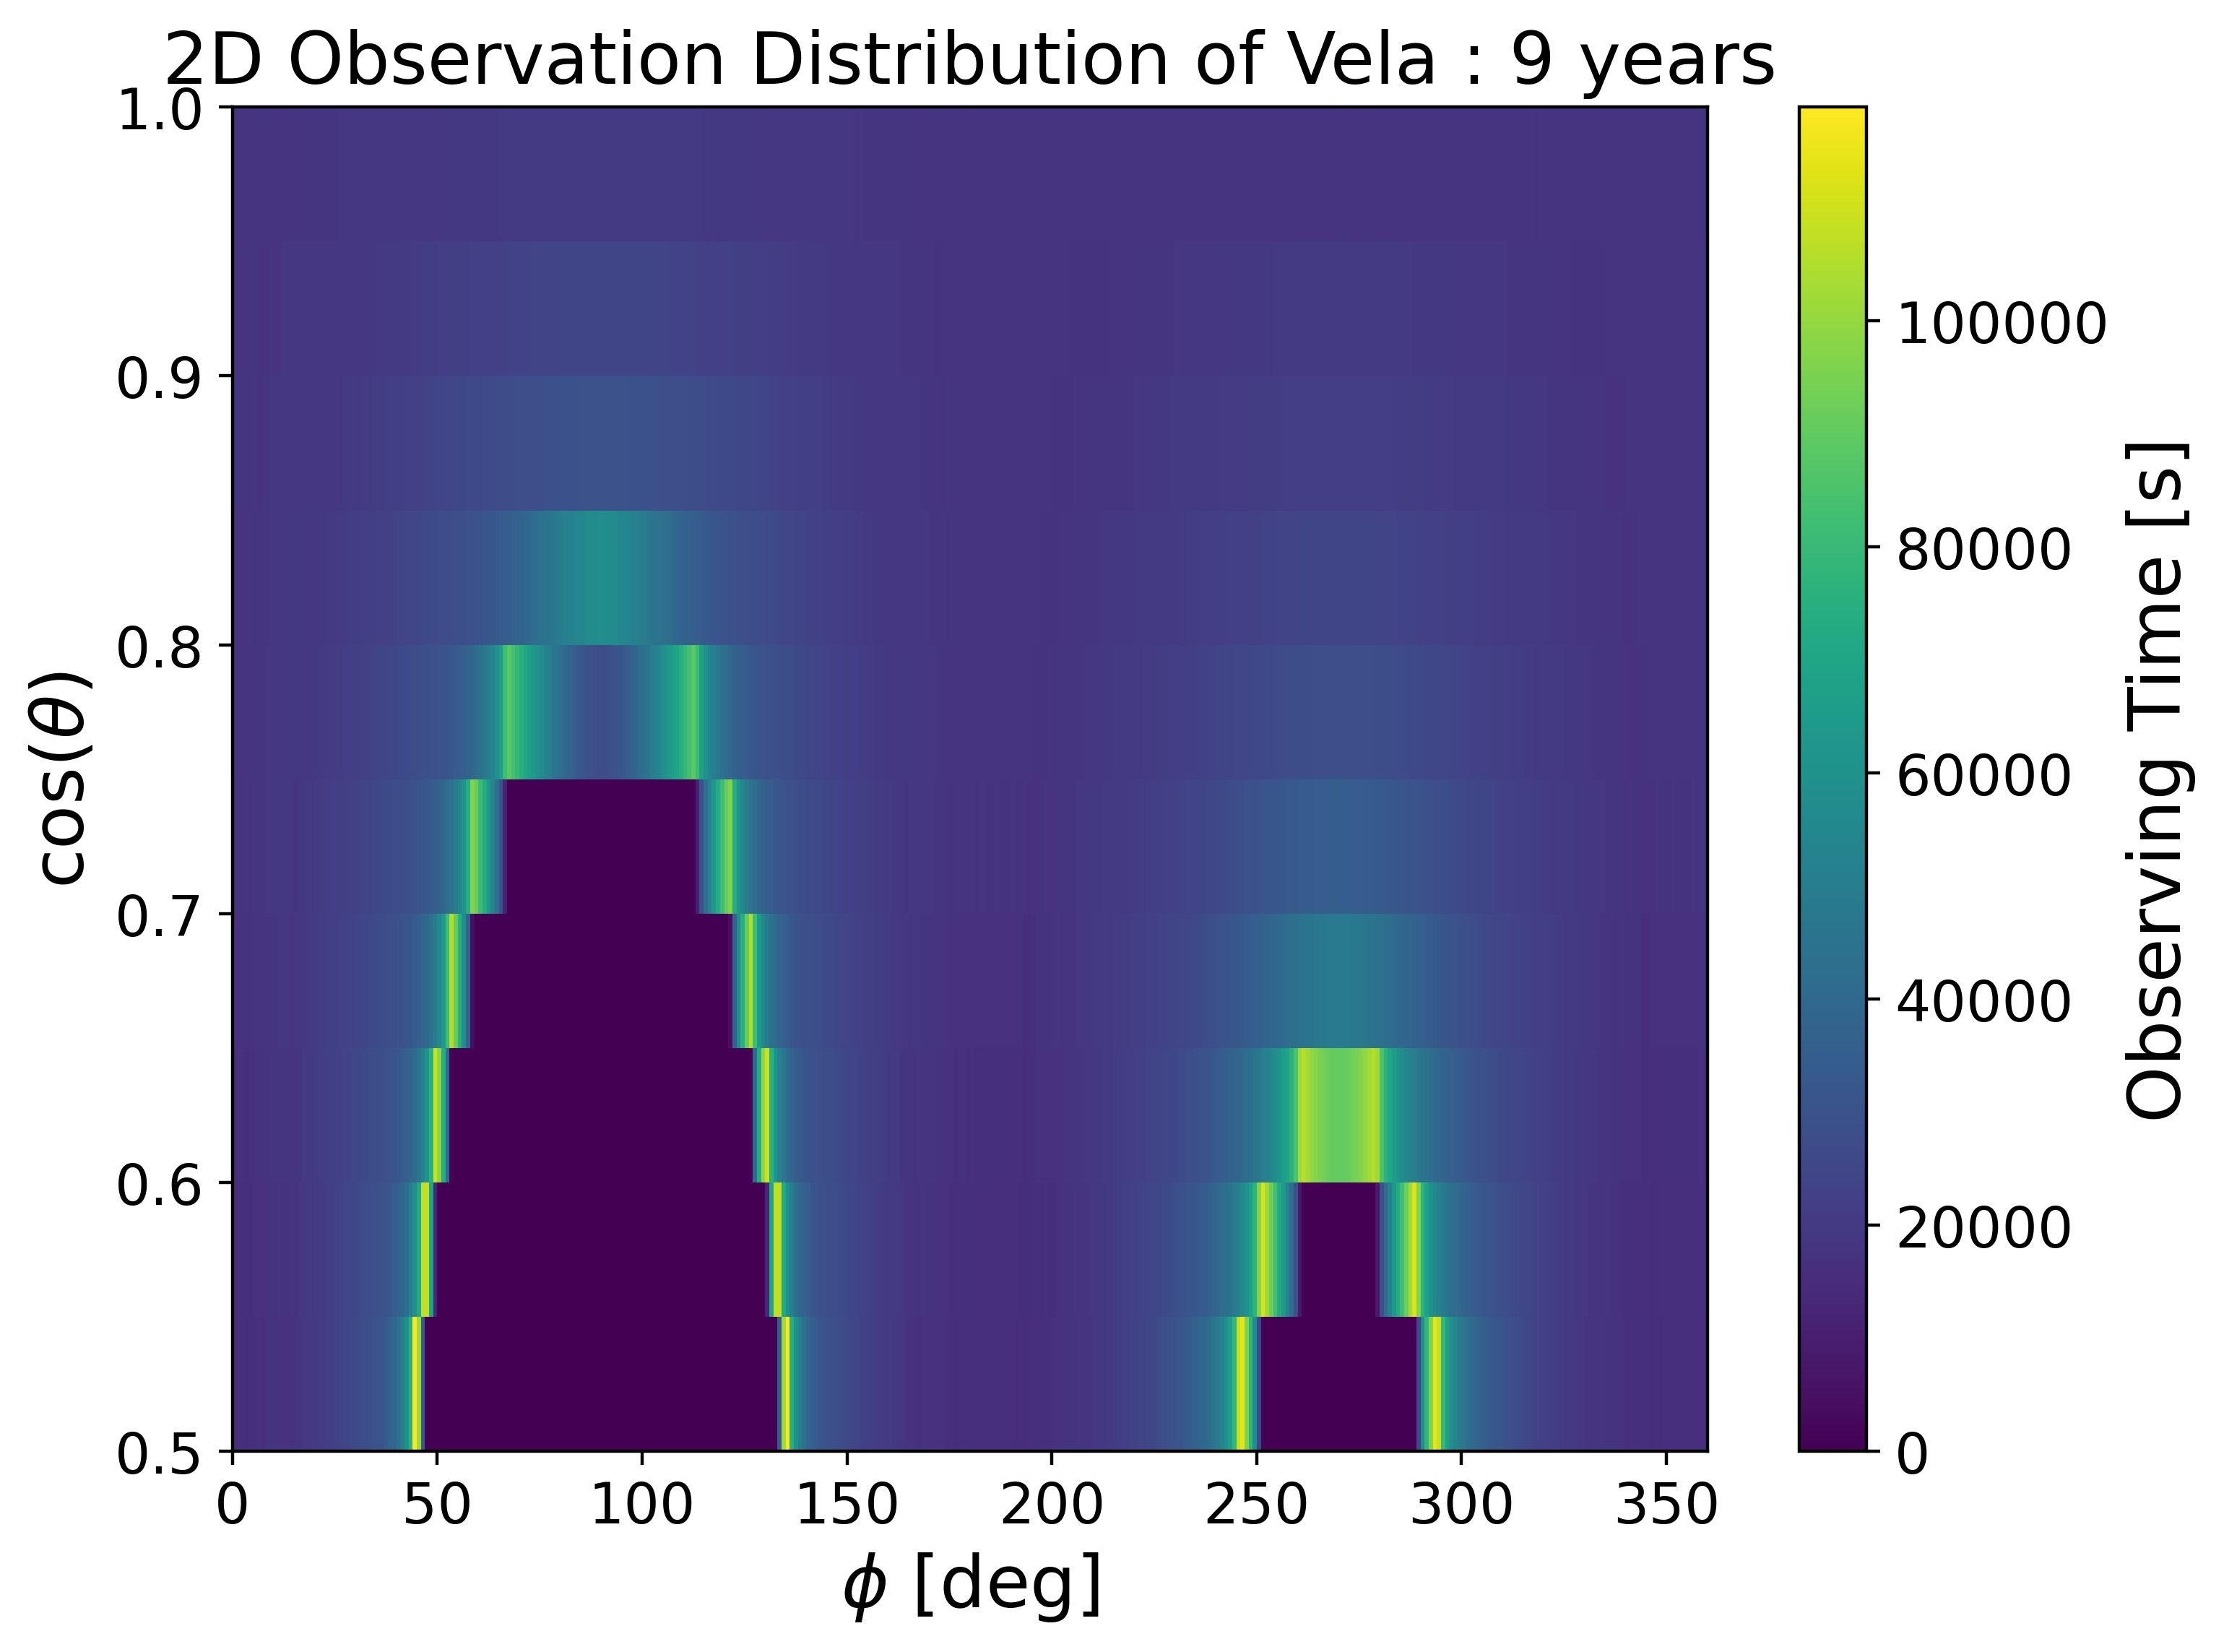

In [12]:
figName = figPath + f"obs_time_{target}.eps"
plot_histogram2d(histogram_total, figName)